# fMRI data (multi-dimensional data)

In [1]:
from matplotlib import pyplot
import pandas
import seaborn
import nibabel
import numpy
import scipy.signal
import spacemed

In [2]:
!pwd # find out, where I am (%cd to switch to the right directory after)

/home/kigr11/Spacemed-2026/kigr11/notebooks


In [3]:
%cd /home/kigr11/Spacemed-2026/kigr11/data

/home/kigr11/Spacemed-2026/kigr11/data


## Load data and look at it

In [4]:
anatomy = nibabel.load("fmri-data/2_Anatomy_1mm_5min.nii")

In [5]:
print (anatomy.header) # show metadata: dimensions, voxel size, voxel size, coordinate system, units

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 54
dim             : [  3 192 256 256   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1.       1.       0.976562 0.976562 2.3      0.       0.       0.      ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b'TE=2.3;Time=170738.945'
aux_file        : b''
qform_code      : scanner
sform_code      : scanner
quatern_b       : -0.027891552075743675
quatern_c       : 0.006216157227754593
quatern_d       : -0.0195028111338615

In [6]:
print(anatomy.shape)
# 256: Number of voxels along the X-axis (e.g., Left to Right).
# 256: Number of voxels along the Y-axis (e.g., Posterior to Anterior).
#v176: Number of voxels along the Z-axis (e.g., Inferior to Superior).

(192, 256, 256)


In [7]:
print(anatomy.header.get_zooms()) # see how big voxels are

(np.float32(1.0), np.float32(0.976562), np.float32(0.976562))


In [8]:
data_anatomy = anatomy.get_fdata() # finally get the voxels and store them

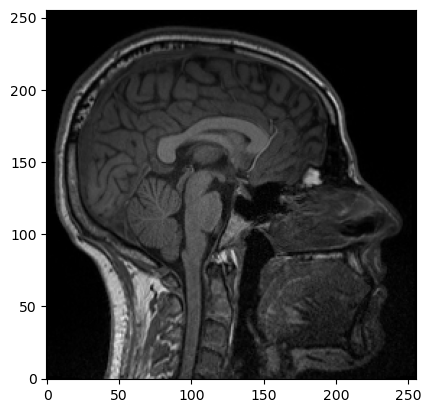

In [9]:
fig, axes = pyplot.subplots(1)
axes.imshow(data_anatomy[96, :, :].T, # inside [] plane, number = number of slice, T changes orientation
    origin="lower",
    cmap="gray")

In [10]:
print(anatomy.affine) # where in the brain am I with my voxels

[[ 9.99162018e-01  3.77299786e-02  1.31960846e-02 -9.83170929e+01]
 [-3.93290296e-02  9.74299788e-01  5.42062148e-02 -1.24112167e+02]
 [-1.13369459e-02 -5.46798818e-02  9.74967122e-01 -1.17133888e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


## Rocket data

In [11]:
ols = pandas.read_csv("ols.csv")

In [12]:
ols

,Vehicle,Length (m),Payload Mass to LEO (kg),Origin,First Flight,Initial Mass (kg)
0,Falcon 9,70.00,22800,USA,2010.0,549000
1,Falcon Heavy,70.00,63800,USA,2018.0,1420000
2,Atlas V,62.50,13550,USA,2002.0,335000
3,Delta IV Heavy,72.00,28370,USA,2002.0,733000
4,SLS Block 1,98.00,95000,USA,2022.0,2600000
5,Starship,120.00,125000,USA,2024.0,5000000
6,Vulcan Centaur,61.00,27200,USA,2023.0,540000
7,Electron,18.00,300,USA,2015.0,12500
8,New Glenn,98.00,45000,USA,2021.0,862000
9,Saturn V,110.60,140000,USA,1967.0,3000000


<Axes: xlabel='Initial Mass (kg)', ylabel='Payload Mass to LEO (kg)'>

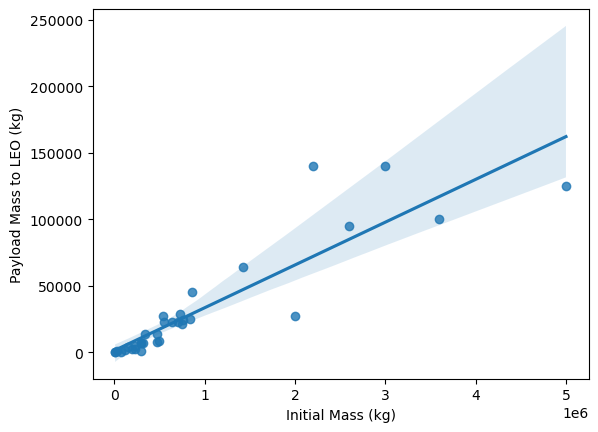

In [13]:
seaborn.regplot(ols,
                x = "Initial Mass (kg)",
                y = "Payload Mass to LEO (kg)",
                order = 1) # how to display: linear, curve,..

## Load one fMRI data type

In [14]:
fmri = nibabel.load("fmri-data/3_fMRI_TR2sec_3mm_3min.nii")

In [15]:
fmri.shape # 4 dimensional, last one is time

(64, 64, 32, 80)

In [16]:
print(fmri.header.get_zooms()) # show resolution of voxels and time (in seconds)

(np.float32(3.0), np.float32(3.0), np.float32(3.75), np.float32(2.0))


In [17]:
nt = fmri.shape [-1] # nt = number of times sampled

In [18]:
sampling_rate = fmri.header.get_zooms()[-1]

In [19]:
print(nt, sampling_rate) # 80 data points, every 2 seconds

80 2.0


In [20]:
p1 = (19,24,25)
p2 = (40,25,25)
p3 = (19,25,25)
# take these time points from the data

In [21]:
fmri_data = fmri.get_fdata() # create a time series

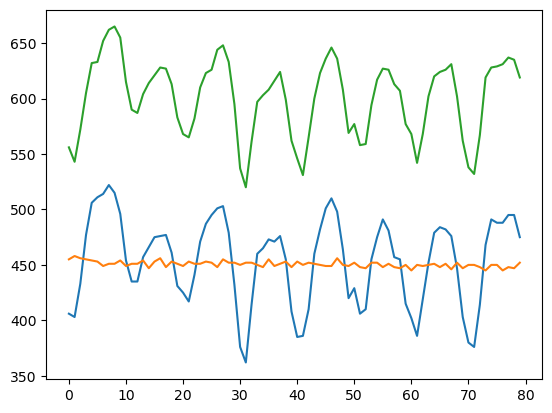

In [22]:
pyplot.plot(fmri_data[p1])
pyplot.plot(fmri_data[p2])
pyplot.plot(fmri_data[p3])

In [23]:
s_one = numpy.array([1]*5 + [0]*5) # s_one = signal one

In [24]:
s_one

array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

In [25]:
nt # nt= number of times I get a sample

80

In [26]:
signal = numpy.tile(s_one, int(numpy.ceil(nt/10)))

In [27]:
signal = signal[:nt]

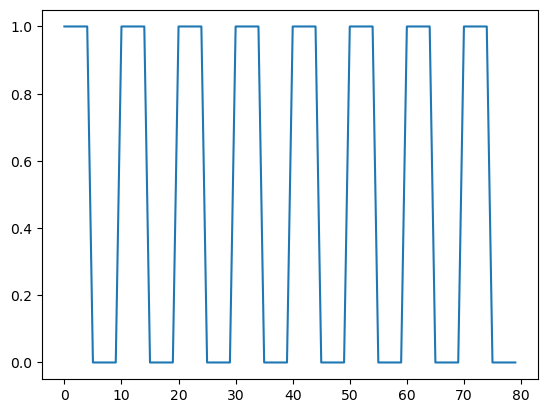

In [28]:
pyplot.plot(signal)

In [29]:
# normalise to compare points: substract to baseline, devide by standarddeviation to normalize amplitude
def normalise(data):
    norm = (data - numpy.mean(data))
    norm = norm / numpy.std(data)
    return norm

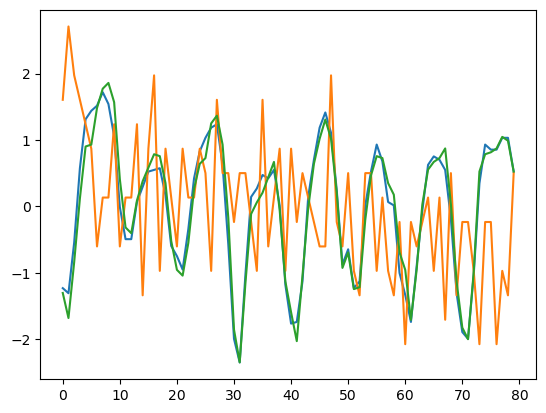

In [30]:
pyplot.plot(normalise(fmri_data[p1]))
pyplot.plot(normalise(fmri_data[p2]))
pyplot.plot(normalise(fmri_data[p3]))

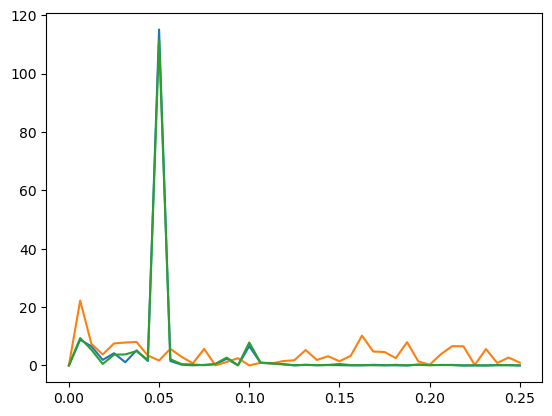

In [31]:
# Frequency analysis
for p in [p1, p2, p3]:
    freq, power = scipy.signal.periodogram(normalise(fmri_data[p]),
                                          fs=1/sampling_rate)
    pyplot.plot(freq, power)

58.11914196096052
11.543840394935287
56.45565951227974


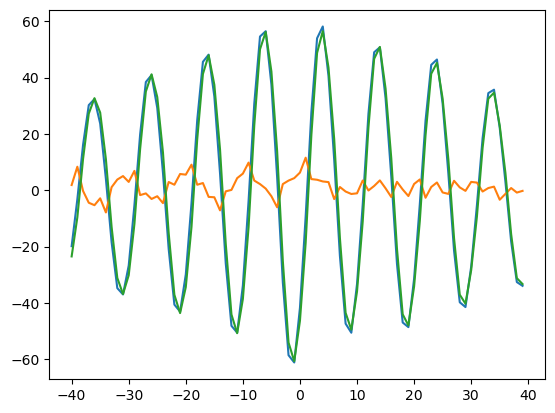

In [32]:
for p in [p1, p2, p3]:
    data = fmri_data[p]
    cross = scipy.signal.correlate(
    # show cross correlation to not just eyeball it 
        normalise(data), normalise(signal),
        mode="same")
    lags = scipy.signal.correlation_lags(
    # lags = it takes e.g. 8 seconds until the brain reacts after an event
       len(data), len(signal),
       mode="same")
    pyplot.plot(lags, cross)
    c = numpy.max(cross) # maximal cross correlation
    print(c)

## Connotations

In [33]:
# condense fMRI-data to 2D
numpy.zeros(fmri.shape[:2])

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(64, 64))

### Call the functions

#### Normalise

In [34]:
normalised_data = spacemed.normalise (fmri_data[p1])

#### Cross correlation

In [36]:
for p in [p1, p2, p3]:
    cross_correlations = spacemed.compute_crosscorrelation("fmri-data/3_fMRI_TR2sec_3mm_3min.nii", signal, data)

NameError: name 'p' is not defined